In [23]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
paths = {
    "stage1": {
        "FC": "./result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy",
        "label": "./result/w_layer/stage1/df_scaled.csv"
    },
    "stage2": {
        "FC": "./result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy",
        "label": "./result/w_layer/stage2/df_scaled.csv"
    },
    "stage3": {
        "FC": "./result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy",
        "label": "./result/w_layer/stage3/df_scaled.csv"
    }
}

region_map_path = "./data/region_map.csv"

   time            type        FC   stage
0     0   layer_related  0.010842  stage1
1     0  layer_to_other  0.006762  stage1
2     0     layer_ratio  1.603459  stage1
3     1   layer_related  0.010849  stage1
4     1  layer_to_other  0.006770  stage1


/tmp/ipykernel_641169/1993845388.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_g, x="stage", y="FC", palette="Set2")


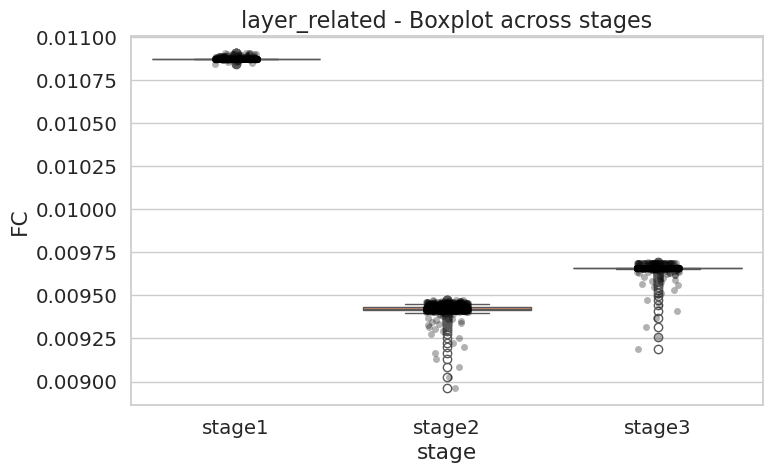

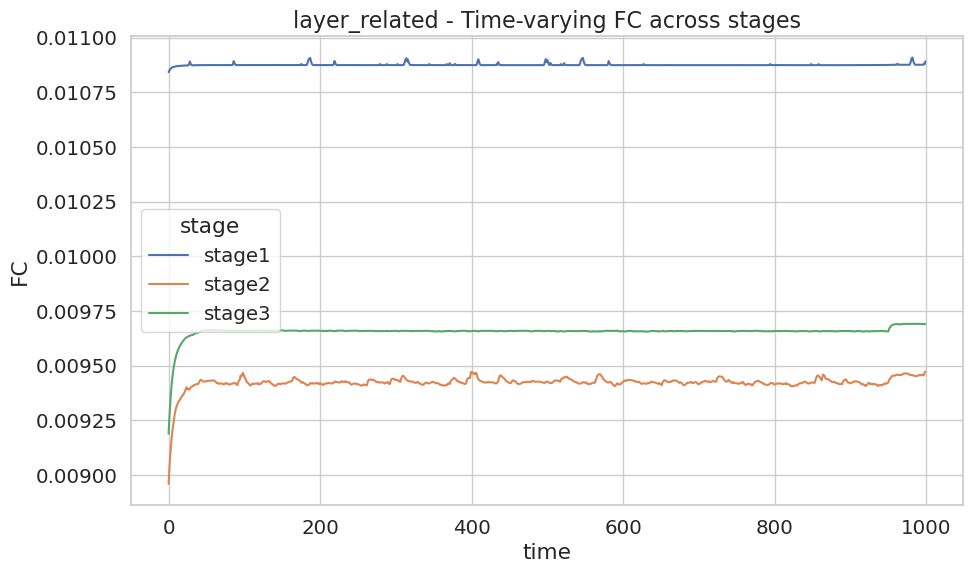

/tmp/ipykernel_641169/1993845388.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_g, x="stage", y="FC", palette="Set2")


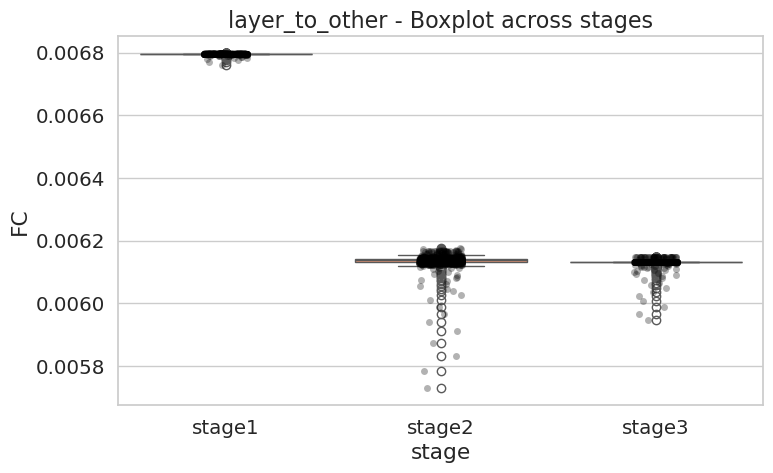

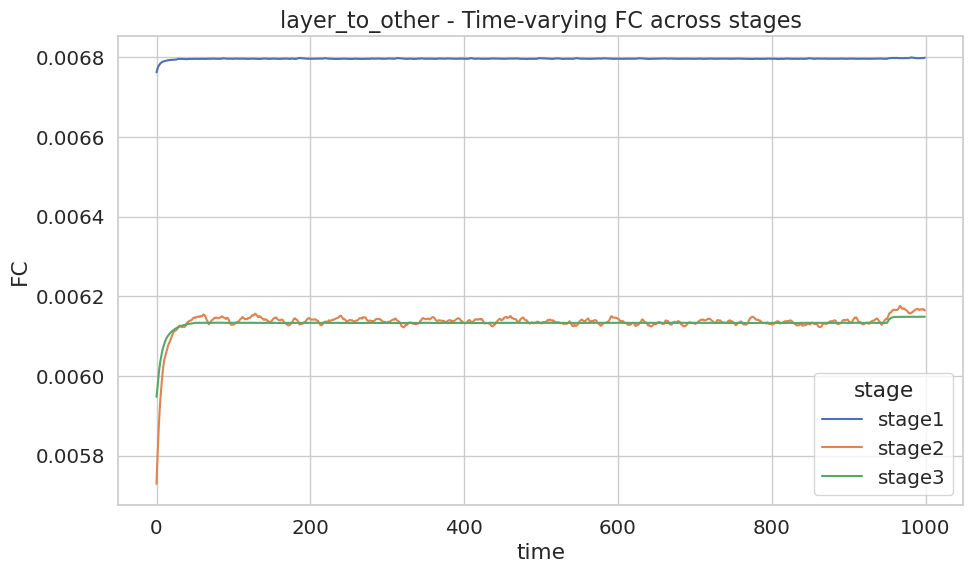

/tmp/ipykernel_641169/1993845388.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_g, x="stage", y="FC", palette="Set2")


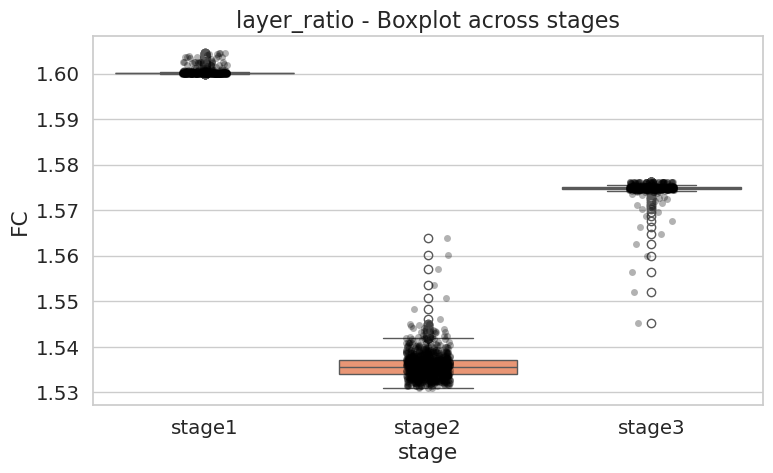

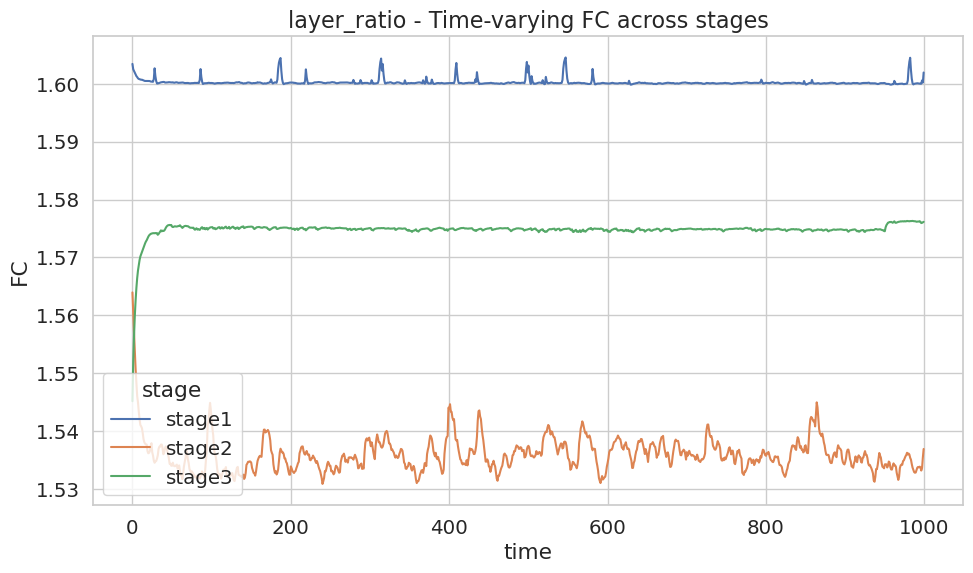

In [15]:

df_map = pd.read_csv(region_map_path, sep="\t")
df_map.columns = ["node_name", "macro_region"]


def compute_layer_types(stage_name, FC_path, label_path):

    FC = np.load(FC_path)                        # (T, N, N)
    region_order = pd.read_csv(label_path).iloc[:, 0].tolist()

    df_nodes = df_map.set_index("node_name").loc[region_order].reset_index()

    macro_counts = df_nodes["macro_region"].value_counts()
    df_nodes["is_layer"] = df_nodes["macro_region"].map(lambda x: macro_counts[x] > 1)

    N = len(df_nodes)
    layer_mask = df_nodes["is_layer"].values

    mask_layer_related = np.zeros((N, N), dtype=bool)
    mask_layer_to_other = np.zeros((N, N), dtype=bool)

    for i in range(N):
        for j in range(N):
            if i == j:
                continue

            if layer_mask[i] and layer_mask[j]:
                mask_layer_related[i, j] = True

            if layer_mask[i] ^ layer_mask[j]:
                mask_layer_to_other[i, j] = True

    stats = {
        "time": [],
        "type": [],
        "FC": [],
        "stage": []
    }

    T = FC.shape[0]
    for t in range(T):
        mat = FC[t]

        val_related = mat[mask_layer_related].mean()
        val_other = mat[mask_layer_to_other].mean()

        # layer_related
        stats["time"].append(t)
        stats["type"].append("layer_related")
        stats["FC"].append(val_related)
        stats["stage"].append(stage_name)

        # layer_to_other
        stats["time"].append(t)
        stats["type"].append("layer_to_other")
        stats["FC"].append(val_other)
        stats["stage"].append(stage_name)

        # ratio = layer_related / layer_to_other
        ratio_val = val_related / val_other if val_other != 0 else np.nan

        stats["time"].append(t)
        stats["type"].append("layer_ratio")
        stats["FC"].append(ratio_val)
        stats["stage"].append(stage_name)

    return pd.DataFrame(stats)


df_all = pd.concat([
    compute_layer_types(stage, paths[stage]["FC"], paths[stage]["label"])
    for stage in ["stage1", "stage2", "stage3"]
])

print(df_all.head())


groups = ["layer_related", "layer_to_other", "layer_ratio"]

for g in groups:
    df_g = df_all[df_all["type"] == g]

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df_g, x="stage", y="FC", palette="Set2")
    sns.stripplot(data=df_g, x="stage", y="FC", color="black", alpha=0.3)

    plt.title(f"{g} - Boxplot across stages", fontsize=16)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df_g, x="time", y="FC", hue="stage")

    plt.title(f"{g} - Time-varying FC across stages", fontsize=16)
    plt.tight_layout()
    plt.show()


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import os


out_dir = "./result/fig"
os.makedirs(out_dir, exist_ok=True)


sns.set_theme(context="paper", style="whitegrid")

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 300,
    "axes.linewidth": 1.0,
})

# group 主色
palette_top = {
    "layer_related": "#F45675",
    "layer_to_other":  "#FAD164",
    "layer_ratio":     "#6B99FD"
}

# stage 配色
stage_palette = {
    "stage1": "#F45675",
    "stage2": "#FAD164",
    "stage3": "#6B99FD"
}

groups = ["layer_related", "layer_to_other", "layer_ratio"]


for g in groups:
    df_g = df_all[df_all["type"] == g]

    fig, ax = plt.subplots(figsize=(12, 10))

    sns.boxplot(
        data=df_g, x="stage", y="FC",
        palette=[palette_top[g]],
        ax=ax, linewidth=1.1, fliersize=2
    )
    sns.stripplot(
        data=df_g, x="stage", y="FC",
        color="black", alpha=0.35, size=2.2, jitter=0.2, ax=ax
    )

    ax.set_title(f"{g.replace('_',' ').title()} Across Stages")
    ax.set_xlabel("Stage")
    ax.set_ylabel("FC")
    sns.despine()

    # 保存 PDF
    boxplot_path = f"{out_dir}/{g}_boxplot.pdf"
    with PdfPages(boxplot_path) as pdf:
        pdf.savefig(fig, dpi=300)
    plt.close(fig)

    print(f"Saved: {boxplot_path}")

    sns.set_style("white")  # 去掉网格

    fig, ax = plt.subplots(figsize=(12, 10))

    sns.lineplot(
        data=df_g, x="time", y="FC", hue="stage",
        palette=stage_palette, linewidth=1.5, ax=ax
    )

    ax.grid(False)  # 禁止网格
    ax.set_title(f"{g.replace('_',' ').title()} Over Time")
    ax.set_xlabel("Time")
    ax.set_ylabel("FC")
    ax.legend(title="Stage", frameon=False)

    sns.despine()

    # 保存 PDF
    timeseries_path = f"{out_dir}/{g}_timeseries.pdf"
    with PdfPages(timeseries_path) as pdf:
        pdf.savefig(fig, dpi=300)
    plt.close(fig)

    print(f"Saved: {timeseries_path}")

    # 恢复 boxplot 风格
    sns.set_theme(context="paper", style="whitegrid")


/tmp/ipykernel_641169/2146217626.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_641169/2146217626.py:57: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


Saved: ./result/fig/layer_related_boxplot.pdf
Saved: ./result/fig/layer_related_timeseries.pdf


/tmp/ipykernel_641169/2146217626.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_641169/2146217626.py:57: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


Saved: ./result/fig/layer_to_other_boxplot.pdf
Saved: ./result/fig/layer_to_other_timeseries.pdf


/tmp/ipykernel_641169/2146217626.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_641169/2146217626.py:57: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


Saved: ./result/fig/layer_ratio_boxplot.pdf
Saved: ./result/fig/layer_ratio_timeseries.pdf


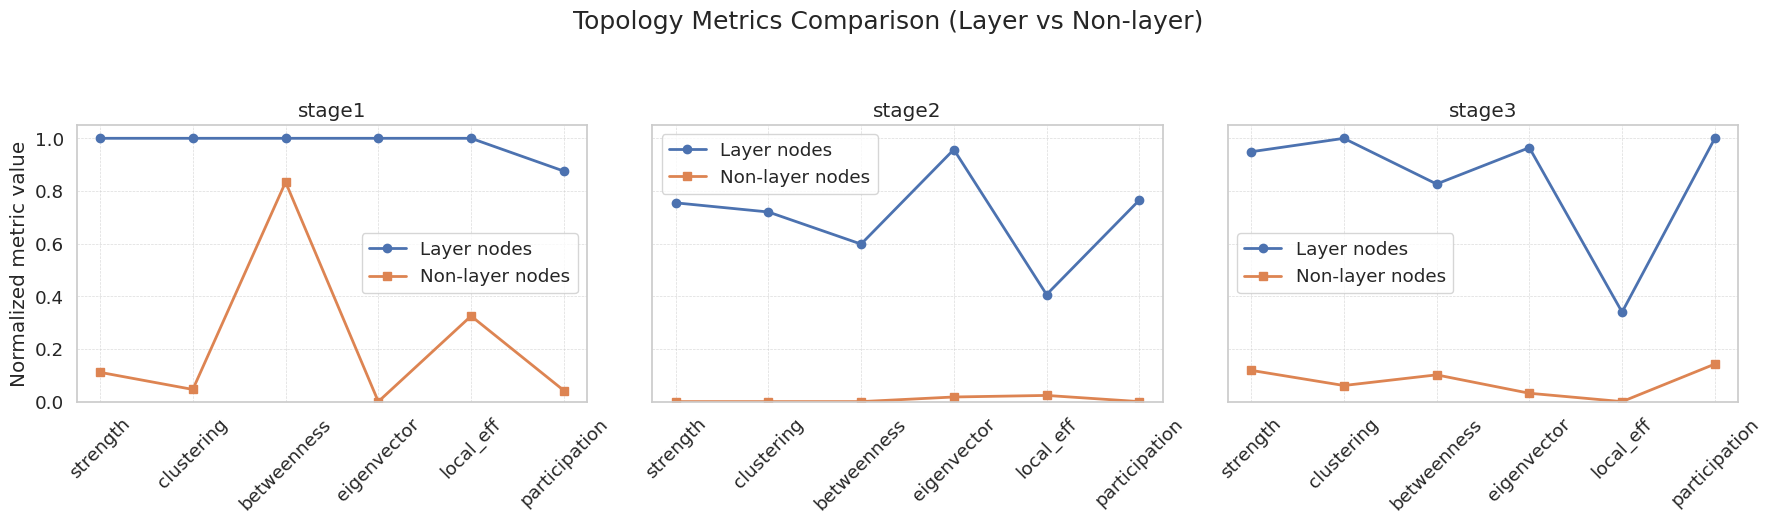

In [21]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

from networkx.algorithms.community import greedy_modularity_communities
from networkx.algorithms.community.quality import modularity



df_map = pd.read_csv(region_map_path, sep="\t")
df_map.columns = ["node_name", "macro_region"]


def build_graph_from_FC(FC_mean, use_abs=True):
    """
    根据平均 FC 构建加权无向图（全部边，无阈值）
    """
    W = np.abs(FC_mean) if use_abs else FC_mean
    N = W.shape[0]

    G = nx.Graph()
    G.add_nodes_from(range(N))

    for i in range(N):
        for j in range(i + 1, N):
            w = W[i, j]
            if w != 0:
                G.add_edge(i, j, weight=float(w))

    return G


# =========================
# local efficiency per node
# =========================
def node_local_efficiency(G):
    eff = {}
    for v in G.nodes():
        neigh = list(G.neighbors(v))

        if len(neigh) < 2:
            eff[v] = 0
            continue

        subG = G.subgraph(neigh)

        path_len = dict(nx.all_pairs_dijkstra_path_length(subG, weight="weight"))
        n = len(neigh)

        S = 0
        for i in subG.nodes():
            for j in subG.nodes():
                if i == j:
                    continue
                d = path_len[i].get(j, np.inf)
                if np.isfinite(d) and d > 0:
                    S += 1 / d
        eff[v] = S / (n * (n - 1))
    return eff


# =========================
# participation coefficient
# =========================
def participation_coefficient(G, partition):
    community_nodes = {}
    for node, cid in partition.items():
        community_nodes.setdefault(cid, []).append(node)

    strength = dict(G.degree(weight="weight"))
    P = {}

    for i in G.nodes():
        k_i = strength[i]
        if k_i == 0:
            P[i] = 0
            continue

        sum_sq = 0
        for cid, members in community_nodes.items():
            k_is = 0
            for j in members:
                if G.has_edge(i, j):
                    k_is += G[i][j]["weight"]
            sum_sq += (k_is / k_i) ** 2

        P[i] = 1 - sum_sq

    return P


# =========================
# 计算每个 stage 的拓扑指标
# =========================
def compute_topology_for_stage(stage_name, FC_path, label_path):

    FC = np.load(FC_path)              # (T, N, N)
    FC_mean = FC.mean(axis=0)

    region_order = pd.read_csv(label_path).iloc[:, 0].tolist()
    df_nodes = df_map.set_index("node_name").loc[region_order].reset_index()

    macro_counts = df_nodes["macro_region"].value_counts()
    df_nodes["is_layer"] = df_nodes["macro_region"].map(lambda x: macro_counts[x] > 1)

    N = len(df_nodes)
    G = build_graph_from_FC(FC_mean, use_abs=True)

    # -------------拓扑指标-------------
    strength = dict(G.degree(weight="weight"))
    clustering = nx.clustering(G, weight="weight")
    betweenness = nx.betweenness_centrality(G, weight="weight", normalized=True)
    eigenvector = nx.eigenvector_centrality(G, max_iter=500, weight="weight")
    local_eff = node_local_efficiency(G)

    # -------------社区划分（无 python-louvain）-------------
    communities = greedy_modularity_communities(G, weight="weight")

    partition = {}
    for cid, comm in enumerate(communities):
        for node in comm:
            partition[node] = cid

    participation = participation_coefficient(G, partition)
    mod_value = modularity(G, communities, weight="weight")

    df_topo = pd.DataFrame({
        "node": np.arange(N),
        "region": df_nodes["node_name"],
        "macro_region": df_nodes["macro_region"],
        "is_layer": df_nodes["is_layer"],
        "strength": [strength[i] for i in range(N)],
        "clustering": [clustering[i] for i in range(N)],
        "betweenness": [betweenness[i] for i in range(N)],
        "eigenvector": [eigenvector[i] for i in range(N)],
        "local_eff": [local_eff[i] for i in range(N)],
        "participation": [participation[i] for i in range(N)],
        "stage": stage_name,
        "graph_modularity": mod_value
    })

    return df_topo


# =========================
# 运行三个 stage
# =========================
df_all_topo = pd.concat([
    compute_topology_for_stage(stage, paths[stage]["FC"], paths[stage]["label"])
    for stage in ["stage1", "stage2", "stage3"]
], ignore_index=True)


# =========================
# 对 layer vs non-layer 进行指标均值
# =========================
metrics = ["strength", "clustering", "betweenness", "eigenvector", "local_eff", "participation"]

summary = []
for stage in ["stage1", "stage2", "stage3"]:
    df_s = df_all_topo[df_all_topo["stage"] == stage]
    for group_name, flag in [("layer", True), ("non_layer", False)]:
        df_g = df_s[df_s["is_layer"] == flag]
        row = {"stage": stage, "group": group_name}
        for m in metrics:
            row[m] = df_g[m].mean()
        summary.append(row)

df_summary = pd.DataFrame(summary)


# =========================
# 归一化 0~1
# =========================
df_plot = df_summary.copy()
for m in metrics:
    vals = df_plot[m].values
    if vals.max() > vals.min():
        df_plot[m] = (vals - vals.min()) / (vals.max() - vals.min())
    else:
        df_plot[m] = 0


# 长格式
df_long = df_plot.melt(
    id_vars=["stage", "group"],
    value_vars=metrics,
    var_name="metric",
    value_name="norm_value"
)



sns.set(style="whitegrid", font_scale=1.2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, stage in zip(axes, ["stage1", "stage2", "stage3"]):

    df_st = df_long[df_long["stage"] == stage]
    pivot = df_st.pivot_table(index="metric", columns="group", values="norm_value")
    pivot = pivot.loc[metrics]

    x = np.arange(len(metrics))
    ax.plot(x, pivot["layer"], marker="o", linewidth=2, label="Layer nodes")
    ax.plot(x, pivot["non_layer"], marker="s", linewidth=2, label="Non-layer nodes")

    ax.set_title(stage)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=45)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linewidth=0.5, linestyle="--", alpha=0.7)

    if ax is axes[0]:
        ax.set_ylabel("Normalized metric value")

    ax.legend()

plt.suptitle("Topology Metrics Comparison (Layer vs Non-layer)", fontsize=18, y=1.05)
plt.tight_layout()
plt.show()


In [32]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import numpy as np

# =============================
# 1. 无网格 & 顶刊风格
# =============================
sns.set(style="white", font_scale=1.2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, stage in zip(axes, ["stage1", "stage2", "stage3"]):

    df_st = df_long[df_long["stage"] == stage]
    pivot = df_st.pivot_table(index="metric", columns="group", values="norm_value")
    pivot = pivot.loc[metrics]

    x = np.arange(len(metrics))

    ax.plot(x, pivot["layer"], marker="o", linewidth=2, label="Layer nodes")
    ax.plot(x, pivot["non_layer"], marker="s", linewidth=2, label="Non-layer nodes")

    ax.set_title(stage, fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=45, ha="right")

    ax.set_ylim(0, 1.05)

    # ❗ 去掉网格
    ax.grid(False)

    # 顶刊风格：干净脊线
    sns.despine(ax=ax)

    if ax is axes[0]:
        ax.set_ylabel("Normalized metric value", fontsize=12)

    ax.legend(frameon=False)

plt.suptitle("Topology Metrics Comparison (Layer vs Non-layer)", fontsize=18, y=1.03)
plt.tight_layout()

# =============================
# 2. 保存为 PDF（矢量图 + 可编辑文字）
# =============================
out_path = "./result/fig/topology_metrics.pdf"

with PdfPages(out_path) as pdf:
    pdf.savefig(fig, dpi=300)   # dpi 只影响 rasterized 元素，矢量保持矢量
plt.close(fig)

print(f"PDF saved to: {out_path}")


PDF saved to: ./result/fig/topology_metrics.pdf
